# Od pixelu ke třídě, pokročilá verze: časová řada, prostorová validace a odhad ploch

[![Otevřít v Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/image_classification_pro_cs.ipynb)

**OpenSkyLab · notebook k vizuálu** [Od pixelu ke třídě](https://openskylab.space/edu_viz_image_classification.html) · [English version](image_classification_pro_en.ipynb)

Pokročilá verze notebooku ke klasifikaci. Místo jednoho snímku pracuješ se třemi snímky Sentinel-2 z jara, léta a podzimu 2024 u Roztok, klasifikátor minimální vzdálenosti si napíšeš sám, přesnost ověříš prostorovou validací a plochy tříd odhadneš i s nejistotou, jak se to dělá v praxi. Část kódu doplňuješ sám.

**Cíl:** sestavit příznaky z časové řady, napsat a ověřit vlastní klasifikátor, porovnat náhodnou a prostorovou validaci, změřit přínos jednotlivých snímků a odhadnout plochy tříd s intervalem spolehlivosti podle dobré praxe (Olofsson a kol. 2014).

**Data:** tři snímky Sentinel-2 L2A dlaždice 33UVR (27. 4., 21. 7. a 21. 9. 2024) z katalogu Earth Search na AWS, výřez 4 × 4 km kolem Roztok a Suchdola; reference ESA WorldCover 10 m 2021 v200. Stahuje se asi 60 MB.

**Úkoly:** pět. Odpovědi piš do buněk *Tvoje odpověď* pod úkoly. Řádky označené `# ◀ parametr` můžeš měnit a buňku spustit znovu (Shift + Enter).

**Čas:** asi 75 min. Potřebuješ Google účet (Colab); nic se neinstaluje do počítače. Buňky spouštěj popořadě shora dolů.

## 1. Příprava a tři snímky

In [1]:
%pip install -q rasterio

Note: you may need to restart the kernel to use updated packages.


In [2]:
import requests, warnings
from itertools import combinations
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import rasterio
from rasterio.warp import reproject, Resampling
from pyproj import Transformer
from sklearn.neighbors import NearestCentroid
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import KFold, GroupKFold, cross_val_score, cross_val_predict
from sklearn.metrics import f1_score
warnings.filterwarnings("ignore")

STAC = "https://earth-search.aws.element84.com/v1/collections/sentinel-2-l2a/items/"
WORLDCOVER = "https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map/ESA_WorldCover_10m_2021_v200_N48E012_Map.tif"
BANDS = ["coastal", "blue", "green", "red", "rededge1", "rededge2", "rededge3", "nir", "nir08", "swir16", "swir22"]

def read_on_grid(url, grid, resampling=Resampling.bilinear, dtype=np.float32):
    """Přečte rastr z cloudu a převzorkuje ho na mřížku grid = (transformace, crs, výška, šířka)."""
    tr, crs, ny, nx = grid
    out = np.zeros((ny, nx), dtype)
    with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", GDAL_HTTP_MAX_RETRY=5, GDAL_HTTP_RETRY_DELAY=2):
        with rasterio.open("/vsicurl/" + url) as src:
            reproject(rasterio.band(src, 1), out, dst_transform=tr, dst_crs=crs, resampling=resampling)
    return out

def s2_window(item_id, lon, lat, half):
    """Odrazivost všech pásem Sentinelu-2 L2A ve čtverci kolem bodu (mřížka 10 m v UTM dlaždice)."""
    item = requests.get(STAC + item_id, timeout=60).json()
    epsg = item["properties"]["proj:epsg"] if "proj:epsg" in item["properties"] else int(item["properties"]["proj:code"].split(":")[1])
    x, y = Transformer.from_crs(4326, epsg, always_xy=True).transform(lon, lat)
    n = int(2 * half / 10)
    grid = (rasterio.transform.from_origin(x - half, y + half, 10, 10), f"EPSG:{epsg}", n, n)
    # od základní linie zpracování 04.00 (2022) mají DN posun +1000; Earth Search ho u novějších položek už odečetl
    p = item["properties"]
    offset = -1000 if float(p.get("s2:processing_baseline", "0")) >= 4 and not p.get("earthsearch:boa_offset_applied", False) else 0
    refl = {b: (read_on_grid(item["assets"][b]["href"], grid) + offset) / 10000 for b in BANDS}
    scl = read_on_grid(item["assets"]["scl"]["href"], grid, Resampling.nearest, np.uint8)
    wl = {b: item["assets"][b]["eo:bands"][0]["center_wavelength"] for b in BANDS}
    return refl, scl, wl, grid, item

S2A_33UVR_20240427_0_L2A: 2024-04-27, bez mraků 99.7% výřezu


S2B_33UVR_20240721_0_L2A: 2024-07-21, bez mraků 99.7% výřezu


S2A_33UVR_20240921_0_L2A: 2024-09-21, bez mraků 100.0% výřezu


pixelů bez mraků ve všech snímcích a v pěti třídách: 158629 (99.1%)


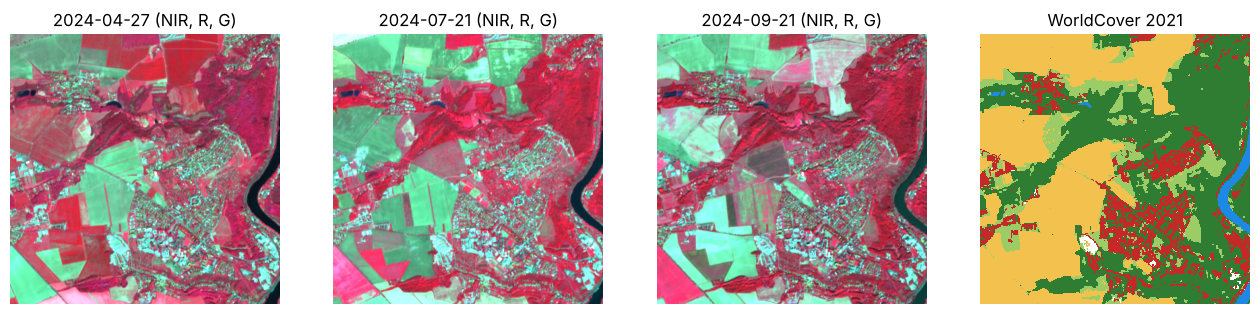

In [3]:
DATES = ["S2A_33UVR_20240427_0_L2A", "S2B_33UVR_20240721_0_L2A", "S2A_33UVR_20240921_0_L2A"]   # ◀ parametr: snímky jednoho roku (jaro, léto, podzim)
LON, LAT, HALF = 14.37, 50.14, 2000                                                          # ◀ parametr: střed výřezu a jeho poloviční šířka (m)
stack, clear = {}, None
for item_id in DATES:
    refl, scl, wl, grid, item = s2_window(item_id, LON, LAT, HALF)
    day = item["properties"]["datetime"][:10]
    stack[day] = refl
    m = np.isin(scl, [4, 5, 6])
    clear = m if clear is None else clear & m
    print(f"{item_id}: {day}, bez mraků {m.mean():.1%} výřezu")
wc = read_on_grid(WORLDCOVER, grid, Resampling.nearest, np.uint8)
CLASSES = {10: "les", 30: "louka", 40: "pole", 50: "zástavba", 80: "voda"}
COLORS = ["#2e7d32", "#9ccc65", "#f2c14e", "#c62828", "#1e88e5"]
names = list(CLASSES.values())
y_img = np.full(wc.shape, -1)
for i, k in enumerate(CLASSES):
    y_img[wc == k] = i
ok = clear & (y_img >= 0)
print(f"pixelů bez mraků ve všech snímcích a v pěti třídách: {ok.sum()} ({ok.mean():.1%})")
fig, ax = plt.subplots(1, len(stack) + 1, figsize=(4 * (len(stack) + 1), 4))
for a, (day, r) in zip(ax, stack.items()):
    a.imshow(np.clip(np.dstack([r["nir"], r["red"], r["green"]]) / np.array([0.45, 0.15, 0.15]), 0, 1)); a.set_title(f"{day} (NIR, R, G)")
ax[-1].imshow(np.ma.masked_less(y_img, 0), cmap=ListedColormap(COLORS), vmin=0, vmax=4, interpolation="nearest"); ax[-1].set_title("WorldCover 2021")
for a in ax: a.axis("off")
plt.show()

## 2. Příznaky z časové řady

Z každého snímku vezmeme odrazivost deseti pásem a tři indexy: NDVI (zeleň), NDWI (voda, McFeeters 1996) a NDMI (vlhkost listů). Se třemi snímky má každý pixel 39 příznaků. Indexy jsou ve slovníku `INDICES` jako funkce a můžeš přidat vlastní.

39 příznaků: blue 04-27, green 04-27, red 04-27, rededge1 04-27, rededge2 04-27, rededge3 04-27, nir 04-27, nir08 04-27 …


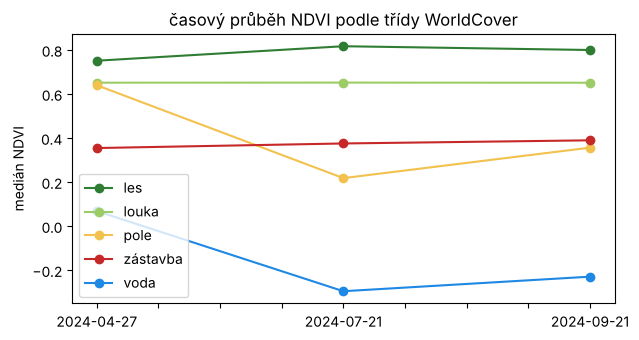

,2024-04-27,2024-07-21,2024-09-21
les,0.75,0.82,0.80
louka,0.65,0.65,0.65
pole,0.64,0.22,0.36
zástavba,0.35,0.38,0.39
voda,0.07,-0.30,-0.23


In [4]:
INDICES = {                                                  # ◀ parametr: indexy počítané z každého snímku; přidej vlastní
    "NDVI": lambda r: (r["nir"] - r["red"]) / (r["nir"] + r["red"]),
    "NDWI": lambda r: (r["green"] - r["nir"]) / (r["green"] + r["nir"]),
    "NDMI": lambda r: (r["nir08"] - r["swir16"]) / (r["nir08"] + r["swir16"]),
}
FEAT_BANDS = ["blue", "green", "red", "rededge1", "rededge2", "rededge3", "nir", "nir08", "swir16", "swir22"]

def features(days):
    """Příznaky pro zvolené dny: odrazivost pásem a indexy. Vrací pole (řádky, sloupce, příznaky) a jejich názvy."""
    F, N = [], []
    for day in days:
        r = stack[day]
        for b in FEAT_BANDS:
            F.append(r[b]); N.append(f"{b} {day[5:]}")
        for name, f in INDICES.items():
            F.append(f(r)); N.append(f"{name} {day[5:]}")
    return np.dstack(F).astype(np.float32), N

DAYS = list(stack)
X_img, feat_names = features(DAYS)
print(f"{len(feat_names)} příznaků:", ", ".join(feat_names[:8]), "…")
prof = pd.DataFrame({day: [np.median(INDICES["NDVI"](stack[day])[ok & (y_img == i)]) for i in range(5)] for day in DAYS}, index=names)
ax = prof.T.plot(marker="o", color=COLORS, figsize=(7, 3.5)); ax.set(ylabel="medián NDVI", title="časový průběh NDVI podle třídy WorldCover"); plt.show()
prof.round(2)

> **✏️ Úkol 1.** Jak se mění medián NDVI louky a pole mezi dubnem, červencem a zářím a proč (osev, sklizeň, seč)? Proč je pro rozlišení pole a louky víc snímků lepší než jeden? Přidej do `INDICES` vlastní index, třeba NDRE = (nir − rededge1) / (nir + rededge1), spusť buňky znovu a v kroku 5 sleduj, jestli pomohl.

*Tvoje odpověď:* 

## 3. Vlastní klasifikátor minimální vzdálenosti

Klasifikátor minimální vzdálenosti přiřadí pixel třídě, jejíž střed (průměrný vektor příznaků) je nejblíž. Napíšeme ho v numpy na pár řádků a ověříme, že dává totéž co `NearestCentroid` ze scikit-learn. Trénujeme na severní polovině výřezu, testujeme na jižní. Větev pro Mahalanobisovu vzdálenost, která bere v úvahu rozptyl a korelace příznaků uvnitř třídy, doplníš sám.

In [5]:
rng = np.random.default_rng(0)
n_class = 600                     # ◀ parametr: vzorek pixelů na třídu
idx = np.flatnonzero(ok.ravel())
samp = np.concatenate([rng.choice(idx[y_img.ravel()[idx] == k], n_class, replace=False) for k in range(5)])
X_all = X_img.reshape(-1, X_img.shape[2])
X, y = X_all[samp], y_img.ravel()[samp]
rows_, cols_ = np.unravel_index(samp, y_img.shape)
train = rows_ < y_img.shape[0] // 2                       # sever trénuje, jih testuje
mu_, sd_ = X[train].mean(0), X[train].std(0)
Xs = (X - mu_) / sd_                                      # standardizace: každý příznak má průměr 0 a rozptyl 1

def min_distance(X_train, y_train, X_test, metric="euclid"):
    """Klasifikace minimální vzdáleností od středu třídy."""
    centres = np.array([X_train[y_train == k].mean(0) for k in range(5)])
    if metric == "euclid":
        d = ((X_test[:, None, :] - centres[None, :, :]) ** 2).sum(2)
    elif metric == "mahalanobis":
        raise NotImplementedError("doplň: kovarianční matice každé třídy, její inverze a vzdálenost (x − μ)ᵀ Σ⁻¹ (x − μ)")
    return d.argmin(1)

metric = "euclid"                 # ◀ parametr: "euclid", nebo po doplnění "mahalanobis"
pred = min_distance(Xs[train], y[train], Xs[~train], metric)
sk = NearestCentroid().fit(Xs[train], y[train]).predict(Xs[~train])
print(f"vlastní klasifikátor ({metric}): přesnost na jihu {np.mean(pred == y[~train]):.1%}; shoda se scikit-learn NearestCentroid {np.mean(pred == sk):.1%}")
qda = QuadraticDiscriminantAnalysis(reg_param=1e-3).fit(Xs[train], y[train])
print(f"maximální věrohodnost (QDA) pro srovnání: {qda.score(Xs[~train], y[~train]):.1%}")

vlastní klasifikátor (euclid): přesnost na jihu 77.1%; shoda se scikit-learn NearestCentroid 100.0%


maximální věrohodnost (QDA) pro srovnání: 82.0%


> **✏️ Úkol 2.** Doplň ve funkci `min_distance` větev `mahalanobis` (kovarianční matice každé třídy z trénovacích pixelů, `np.linalg.inv`, vzdálenost (x − μ)ᵀ Σ⁻¹ (x − μ)) a nastav `metric = "mahalanobis"`. Jak se výsledek srovná s eukleidovskou vzdáleností a s QDA? QDA je maximální věrohodnost: proč se od tvé Mahalanobisovy vzdálenosti přesto liší (člen s ln |Σ| a apriorní pravděpodobnosti)? Proč je u eukleidovské vzdálenosti nutná standardizace? Zkus ji vypnout (`Xs = X`).

*Tvoje odpověď:* 

## 4. Náhodná, nebo prostorová validace?

Sousední pixely si jsou podobné. Když vzorek rozdělíme na trénovací a testovací náhodně, testovací pixel má často souseda v tréninku a přesnost vyjde příliš dobře. Prostorová validace dělí vzorek po čtvercích: celý čtverec je buď v tréninku, nebo v testu (Roberts a kol. 2017). Porovnáme náhodné rozdělení, čtverce a rozdělení na sever a jih.

In [6]:
BLOCK_M = 500                     # ◀ parametr: velikost čtverců pro prostorovou validaci (m)
rf = RandomForestClassifier(200, max_depth=12, random_state=0, n_jobs=-1)
blocks = (rows_ * 10 // BLOCK_M) * 10000 + cols_ * 10 // BLOCK_M
cv = {
    "náhodné rozdělení (KFold)": cross_val_score(rf, X, y, cv=KFold(5, shuffle=True, random_state=0)),
    f"čtverce {BLOCK_M} m (GroupKFold)": cross_val_score(rf, X, y, cv=GroupKFold(5), groups=blocks),
    "sever × jih": np.array([rf.fit(X[train], y[train]).score(X[~train], y[~train]), rf.fit(X[~train], y[~train]).score(X[train], y[train])]),
}
print(f"čtverců s aspoň jedním pixelem vzorku: {len(np.unique(blocks))}")
pd.DataFrame({k: {"průměr": v.mean(), "min": v.min(), "max": v.max()} for k, v in cv.items()}).T.round(3)

čtverců s aspoň jedním pixelem vzorku: 64


,průměr,min,max
náhodné rozdělení (KFold),0.900,0.893,0.910
čtverce 500 m (GroupKFold),0.892,0.854,0.926
sever × jih,0.852,0.835,0.869


> **✏️ Úkol 3.** Proč vychází náhodné rozdělení nejlépe a rozdělení sever × jih nejhůř? Nastav `BLOCK_M` na 200 a 1000 m: jak se mění průměr a rozptyl přesnosti a proč? Kterému číslu bys věřil, kdyby se mapa měla použít na sousedním území, a které bys uvedl ve zprávě?

*Tvoje odpověď:* 

## 5. Co přinese který snímek

Průběh v čase odliší třídy, které jsou v jednom okamžiku podobné. Spočítáme přesnost náhodného lesa (prostorová validace po čtvercích) pro každý snímek zvlášť, pro dvojice i pro všechny tři, a míru F1 každé třídy pro letní snímek a pro všechny tři.

In [7]:
day_of = np.array([n.split()[-1] for n in feat_names])
rows = {}
for r_ in range(1, len(DAYS) + 1):
    for combo in combinations(DAYS, r_):
        cols = np.isin(day_of, [d[5:] for d in combo])
        acc = cross_val_score(rf, X[:, cols], y, cv=GroupKFold(5), groups=blocks)
        rows[" + ".join(d[5:] for d in combo)] = {"příznaků": int(cols.sum()), "přesnost (čtverce)": acc.mean()}
res = pd.DataFrame(rows).T
print(res.round(3).to_string())
one, allc = np.isin(day_of, DAYS[1][5:]), np.ones(len(day_of), bool)
f1 = {}
for label, cols in [(f"jen {DAYS[1][5:]}", one), ("všechny snímky", allc)]:
    pr = cross_val_predict(rf, X[:, cols], y, cv=GroupKFold(5), groups=blocks)
    f1[label] = f1_score(y, pr, average=None)
pd.DataFrame(f1, index=names).round(2)

                       příznaků  přesnost (čtverce)
04-27                      13.0               0.831
07-21                      13.0               0.845
09-21                      13.0               0.849
04-27 + 07-21              26.0               0.879
04-27 + 09-21              26.0               0.883
07-21 + 09-21              26.0               0.876
04-27 + 07-21 + 09-21      39.0               0.892


,jen 07-21,všechny snímky
les,0.80,0.84
louka,0.75,0.81
pole,0.86,0.94
zástavba,0.83,0.87
voda,0.98,0.99


> **✏️ Úkol 4.** Který samotný snímek je nejlepší a která dvojice? O kolik pomohly všechny tři snímky a u které třídy nejvíc? Vysvětli to grafem NDVI z kroku 2. Kdy by další snímek už nepomohl a co by pak pomohlo víc (jiné příznaky, lepší reference, víc trénovacích pixelů)?

*Tvoje odpověď:* 

## 6. Mapa a odhad ploch s nejistotou

Plocha třídy spočítaná z mapy (počet pixelů krát plocha pixelu) je zatížená chybami klasifikace. Dobrá praxe (Olofsson a kol. 2014) je odhadnout plochu z náhodného vzorku kontrolních pixelů vybraného zvlášť v každé třídě mapy (stratifikovaný výběr) a uvést interval spolehlivosti. Mapu vytvoříme z poloviny čtverců a plochy odhadneme na zbytku území. Referencí je tu WorldCover, který máme pro všechny pixely, takže můžeme odhad porovnat se skutečným součtem.

území 792 ha, celková přesnost 86.3%, kontrolních pixelů 500


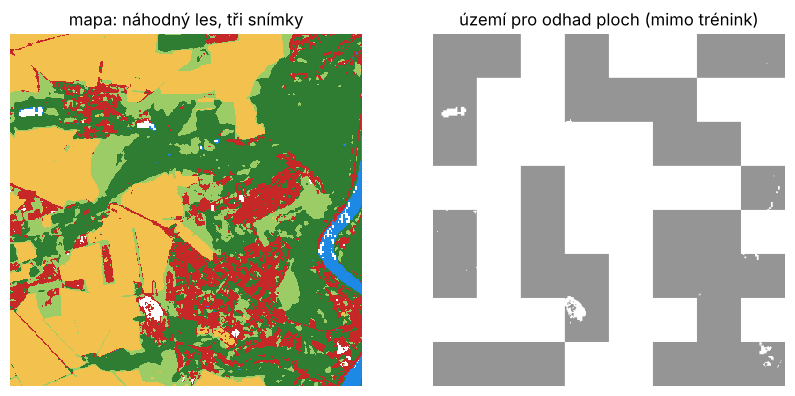

,z mapy (ha),odhad ze vzorku (ha),± 95 % (ha),WorldCover všech pixelů (ha),přesnost uživatele,přesnost zpracovatele
les,290.34,331.77,19.38,325.79,0.94,0.82
louka,110.17,84.80,16.41,87.96,0.60,0.78
pole,256.38,280.69,10.78,278.11,1.00,0.91
zástavba,118.02,79.55,13.17,85.90,0.62,0.92
voda,17.29,15.39,1.07,14.44,0.89,1.00


In [8]:
n_h = 100                         # ◀ parametr: vzorek kontrolních pixelů v každé třídě mapy
blk = (np.indices(y_img.shape)[0] * 10 // BLOCK_M) * 10000 + np.indices(y_img.shape)[1] * 10 // BLOCK_M
ub = np.unique(blk)
train_blocks = rng.choice(ub, len(ub) // 2, replace=False)
in_train = np.isin(blk, train_blocks).ravel() & ok.ravel()
pool = np.flatnonzero(in_train)
tr = np.concatenate([rng.choice(pool[y_img.ravel()[pool] == k], min(400, int((y_img.ravel()[pool] == k).sum())), replace=False) for k in range(5)])
rf.fit(X_all[tr], y_img.ravel()[tr])
mapped = np.full(y_img.size, -1)
mapped[ok.ravel()] = rf.predict(X_all[ok.ravel()])
area = ok.ravel() & ~in_train                              # území mimo trénovací čtverce
W = np.array([np.mean(mapped[area] == h) for h in range(5)])
cm = np.zeros((5, 5))
for h in range(5):
    s = rng.choice(np.flatnonzero(area & (mapped == h)), n_h, replace=False)
    cm[h] = np.bincount(y_img.ravel()[s], minlength=5)
n_i = cm.sum(1, keepdims=True)
p = W[:, None] * cm / n_i                                  # odhad podílů plochy (řádek = mapa, sloupec = reference)
se = np.sqrt((W[:, None] ** 2 * (cm / n_i) * (1 - cm / n_i) / (n_i - 1)).sum(0))
A = area.sum() * 100 / 1e4                                 # ha
out = pd.DataFrame({"z mapy (ha)": W * A, "odhad ze vzorku (ha)": p.sum(0) * A, "± 95 % (ha)": 1.96 * se * A,
                    "WorldCover všech pixelů (ha)": [np.mean(y_img.ravel()[area] == k) * A for k in range(5)],
                    "přesnost uživatele": np.diag(cm) / n_i[:, 0], "přesnost zpracovatele": np.diag(p) / p.sum(0)}, index=names)
print(f"území {A:.0f} ha, celková přesnost {np.trace(p):.1%}, kontrolních pixelů {int(cm.sum())}")
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(np.ma.masked_less(mapped.reshape(y_img.shape), 0), cmap=ListedColormap(COLORS), vmin=0, vmax=4, interpolation="nearest"); ax[0].set_title("mapa: náhodný les, tři snímky")
ax[1].imshow(np.where(area.reshape(y_img.shape), 1.0, np.nan), cmap="Greys", vmin=0, vmax=2); ax[1].set_title("území pro odhad ploch (mimo trénink)")
for a in ax: a.axis("off")
plt.show()
out.round(2)

> **✏️ Úkol 5.** Které třídy mapa nadhodnocuje a které podhodnocuje? Je blíž součtu WorldCoveru plocha z mapy, nebo odhad ze vzorku, a leží součet v intervalu ±95 %? Nastav `n_h` na 30 a 300: jak se mění interval a proč? V praxi referenci pro všechny pixely nemáš: proč pak plocha z mapy nestačí? A proč ani WorldCover není „pravda“ (jeho celková přesnost je kolem 77 %, Zanaga a kol. 2022)?

*Tvoje odpověď:* 

> **✏️ Rozšíření (nepovinné).** Vyzkoušej jiné místo: najdi v katalogu Earth Search tři bezoblačné snímky jednoho roku (jaro, léto, podzim), změň `DATES`, `LON` a `LAT` a podle zeměpisné polohy i dlaždici WorldCover v proměnné `WORLDCOVER` (dlaždice 3 × 3°, např. N48E015 pro Moravu). Vyjdou závěry kroků 4 až 6 stejně?

*Tvoje odpověď:* 

---
### Zdroje dat a literatura

- Copernicus Sentinel-2 data 2024, ESA (L2A, Sen2Cor); registr AWS Open Data (`sentinel-cogs`), katalog Earth Search (Element 84). Volné užití s uvedením zdroje.
- Zanaga, D. a kol. (2022). *ESA WorldCover 10 m 2021 v200*. https://doi.org/10.5281/zenodo.7254221 (CC BY 4.0).
- Olofsson, P., Foody, G. M., Herold, M., Stehman, S. V., Woodcock, C. E., Wulder, M. A. (2014). Good practices for estimating area and assessing accuracy of land change. *Remote Sensing of Environment* 148, 42–57. https://doi.org/10.1016/j.rse.2014.02.015
- Roberts, D. R. a kol. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography* 40, 913–929. https://doi.org/10.1111/ecog.02881
- Congalton, R. G., Green, K. (2019). *Assessing the Accuracy of Remotely Sensed Data: Principles and Practices*, 3. vyd. CRC Press.
- Pedregosa, F. a kol. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research* 12, 2825–2830.

### Jak citovat

OpenSkyLab (2026). Od pixelu ke třídě, pokročilá verze: časová řada, prostorová validace a odhad ploch [notebook, výukový materiál], verze 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/image_classification_pro_cs.ipynb. Licence CC BY 4.0.

Text a kód notebooku: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data mají licence svých poskytovatelů (viz výše).

*Materiál připravil tým OpenSkyLab s pomocí generativní AI Claude (Anthropic), která pomáhala s návrhem kódu a textu. Za obsah odpovídají autoři.*